# Análise de Desempenho - Simulador de Livro de Ofertas

Disciplina: Estrutura de Dados em Python - Prof. Marcos Mansano Furlan

Este notebook documenta a análise teórica (Big-O) e a análise empírica (benchmarks reais) das estruturas implementadas pelo grupo: Fila, Pilha, Lista Duplamente Encadeada Ordenada (Livro de Ofertas) e o Motor de Match.

## 1. Análise teórica de complexidade

### 1.1 Fila de Entrada (FIFO)

As operações `enfileira` e `desenfileira` manipulam apenas as referências `head` e `tail` da fila, sem percorrer nenhum nó intermediário.

- **Enqueue:** O(1)
- **Dequeue:** O(1)

### 1.2 Pilha de Undo (LIFO)

As operações `empilha` e `desempilha` manipulam apenas a referência `topo`.

- **Push:** O(1)
- **Pop:** O(1)

### 1.3 Livro de Ofertas (Lista Duplamente Encadeada Ordenada)

A inserção (`inserecompra` / `inserevenda`) precisa manter a lista ordenada por preço (decrescente para compras, crescente para vendas). Para isso, o código percorre os nós em um laço `while` até encontrar a posição correta.

- **Inserção ordenada:** O(n) no pior caso, pois pode percorrer toda a lista
- **Remoção (`removecompra` / `removevenda`):** O(1), pois a função recebe a referência direta do nó a remover, sem precisar buscar

### 1.4 Motor de Match

O laço de `executar_match` roda enquanto houver um match possível (preço de compra ≥ preço de venda no topo das listas). Cada iteração realiza apenas comparações e operações O(1) (atualização de quantidade, empilhar transação, remoção O(1)).

- **Custo por match:** O(1)
- **Custo total de uma chamada:** O(k), onde k = número de matches executados naquela chamada

In [1]:
import sys, os
import time
import random

# Garante que o pacote do projeto seja encontrado a partir da pasta /analise
sys.path.append(os.path.abspath(".."))

from pacote.ordem import Ordem
from pacote.entrada_undo import Fila, Pilha
from pacote.livro_ofertas import ListaCompras, ListaVendas
from pacote.motor_match import executar_match, PilhaTransacoes

## 2. Gerador de massa de dados

In [2]:
def gerar_ordens(n, seed=None):
    """Gera n ordens aleatórias no formato (tipo, preço, quantidade)."""
    if seed is not None:
        random.seed(seed)
    ordens = []
    for _ in range(n):
        tipo = random.choice(["C", "V"])
        preco = round(random.uniform(10.0, 100.0), 2)
        quantidade = random.randint(1, 500)
        ordens.append((tipo, preco, quantidade))
    return ordens

## 3. Benchmark 1 - Inserção pura no Livro de Ofertas

Mede apenas o custo de inserir N ordens, isolando o comportamento O(n) da lista (sem fila, sem match).

In [3]:
def benchmark_insercao(n, seed=42):
    massa = gerar_ordens(n, seed=seed)
    lista_compras = ListaCompras()
    lista_vendas = ListaVendas()

    inicio = time.perf_counter()
    for tipo, preco, quantidade in massa:
        ordem = Ordem(tipo, preco, quantidade)
        if tipo == "C":
            lista_compras.inserecompra(ordem)
        else:
            lista_vendas.inserevenda(ordem)
    fim = time.perf_counter()
    return fim - inicio


volumes = [100, 500, 1000, 5000, 10000]
tempos_insercao = []

for n in volumes:
    t = benchmark_insercao(n)
    tempos_insercao.append(t)
    print(f"N={n:>6} -> {t:.4f} s")

N=   100 -> 0.0008 s
N=   500 -> 0.0106 s
N=  1000 -> 0.0744 s
N=  5000 -> 0.4785 s
N= 10000 -> 2.7927 s


## 4. Benchmark 2 - Sistema completo (Fila + Inserção + Motor de Match)

Simula o fluxo real do `main.py`: as ordens entram na fila, são processadas uma a uma (inseridas no livro e, em seguida, o motor tenta executar um match).

In [4]:
def benchmark_sistema_completo(n, seed=42):
    massa = gerar_ordens(n, seed=seed)

    fila_de_entrada = Fila()
    lista_compras = ListaCompras()
    lista_vendas = ListaVendas()
    pilha_undo = Pilha()
    pilha_transacoes = PilhaTransacoes()

    for tipo, preco, quantidade in massa:
        fila_de_entrada.enfileira(tipo, preco, quantidade)

    inicio = time.perf_counter()
    while not fila_de_entrada.esta_vazia():
        ordem = fila_de_entrada.desenfileira()
        if ordem.tipo == "C":
            lista_compras.inserecompra(ordem)
        else:
            lista_vendas.inserevenda(ordem)
        pilha_undo.empilha(ordem.id)
        executar_match(lista_compras, lista_vendas, pilha_transacoes)
    fim = time.perf_counter()
    return fim - inicio


tempos_sistema = []
for n in volumes:
    t = benchmark_sistema_completo(n)
    tempos_sistema.append(t)
    print(f"N={n:>6} -> {t:.4f} s")

N=   100 -> 0.0006 s
N=   500 -> 0.0024 s
N=  1000 -> 0.0049 s
N=  5000 -> 0.0397 s
N= 10000 -> 0.1107 s


## 5. Gráficos

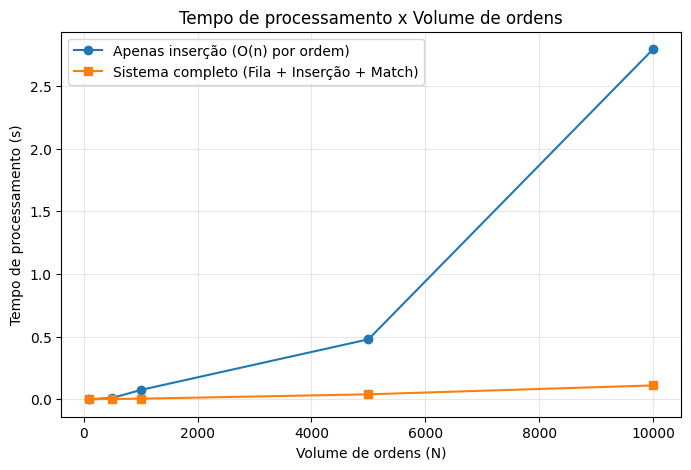

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(volumes, tempos_insercao, marker="o", label="Apenas inserção (O(n) por ordem)")
plt.plot(volumes, tempos_sistema, marker="s", label="Sistema completo (Fila + Inserção + Match)")
plt.xlabel("Volume de ordens (N)")
plt.ylabel("Tempo de processamento (s)")
plt.title("Tempo de processamento x Volume de ordens")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 6. Conclusão - Comparação com Árvores

Como a inserção no Livro de Ofertas é O(n), o custo de processar um lote de N ordens tende a O(n²) no total (N inserções, cada uma custando até O(n)). Isso explica o crescimento acelerado observado nos gráficos acima conforme N aumenta.

Se o Livro de Ofertas fosse implementado com uma **Árvore Binária de Busca balanceada (AVL ou Árvore Rubro-Negra)**, a inserção ordenada cairia de O(n) para **O(log n)**, e o custo total do lote cairia de O(n²) para O(n log n) - uma melhora significativa para sistemas de alto volume, como um motor de negociação financeira real.

Note-se que o Benchmark 2 cresce de forma mais suave que o Benchmark 1. Isso ocorre porque a geração aleatória de preços causa matches frequentes, mantendo o livro de ofertas pequeno — o que mascara o pior caso O(n²) da estrutura. O Benchmark 1, isolando a inserção, revela o comportamento real e justifica a necessidade de uma árvore para cenários de alto volume sem matches imediatos (ex: mercados com spread alto entre compra e venda).